Generating waveform with phenomxpy IMRPhenomTHM...
Trying IMRPhenomTHM with kwargs:
  eta = 0.25
  total_mass = 1000000.0
  distance = 6230.0
  s1 = 0.3
  s2 = -0.2
  f_min = 0.0001
  iota = 0.7
  phi_ref = 0.0

compute_polarizations returned 3 objects
  output[0]: shape=(72000,), dtype=float64
  output[1]: shape=(72000,), dtype=float64
  output[2]: shape=(72000,), dtype=float64

Saved waveform file:
  /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/inputs/my_waveform.npz
  N       = 72000
  dt      = 0.1 s
  t range = [-3600, 3599.9] s
  hplus   range = [-1.790e-18, 1.908e-18]
  hcross  range = [-1.877e-18, 1.847e-18]


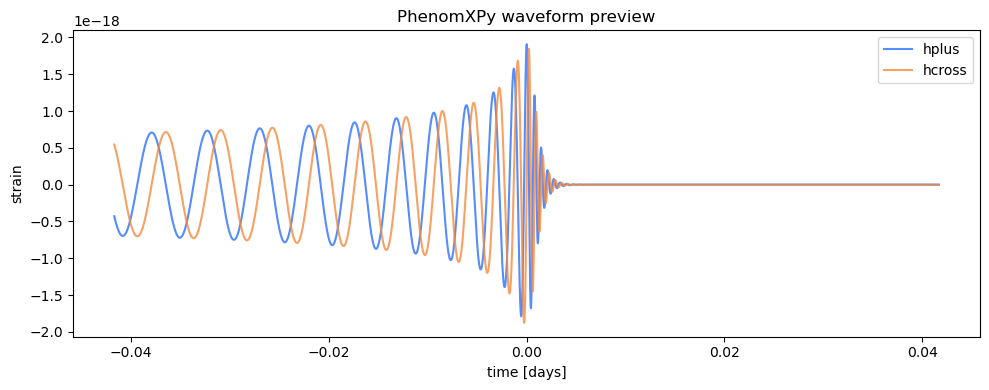


Saved preview plot:
  /Users/shubhanshutiwari/IdeaProjects/LISA-TF/lisa_link_sim/outputs/phenomxpy_waveform_preview.png


In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Import phenomxpy
# ============================================================

try:
    from phenomxpy import IMRPhenomTHM
except ImportError as exc:
    raise ImportError(
        "Could not import phenomxpy. Install it with:\n\n"
        "    pip install phenomxpy\n\n"
        "or from source:\n\n"
        "    git clone https://gitlab.com/imrphenom-dev/phenomxpy.git\n"
        "    cd phenomxpy\n"
        "    pip install .\n"
    ) from exc


# ============================================================
# Explicit paths
# ============================================================
# Notebook-safe:
# If running from inside lisa_link_sim/, use:
#     BASE_DIR = Path.cwd()
#
# If running from pipeline root, use:
#     BASE_DIR = Path.cwd() / "lisa_link_sim"
#
# If saving as a .py script inside lisa_link_sim/, you may use:
#     BASE_DIR = Path(__file__).resolve().parent

BASE_DIR = Path.cwd()

# Uncomment this if your notebook current directory is the pipeline root:
# BASE_DIR = Path.cwd() / "lisa_link_sim"

INPUT_DIR = BASE_DIR / "inputs"
OUTPUT_DIR = BASE_DIR / "outputs"

INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WAVEFORM_FILE = INPUT_DIR / "my_waveform.npz"
PLOT_FILE = OUTPUT_DIR / "phenomxpy_waveform_preview.png"


# ============================================================
# Waveform settings
# ============================================================

# Time grid
dt = 0.1                       # seconds
duration = 3600.0       # 3 days
times = np.arange(-duration, duration, dt)

# Binary parameters
# Start with simple aligned-spin MBHB-like values.
eta = 0.25                       # symmetric mass ratio, 0 < eta <= 0.25
total_mass = 1.0e6               # total mass; phenomxpy docs use SI output when total_mass and distance are set
distance = 6230.0                # luminosity distance [Mpc]
s1 = 0.3                         # spin 1
s2 = -0.2                        # spin 2

# Your installed version complained about f_min, so use f_min.
f_min = 1.0e-4                   # Hz

# Optional: source inclination / phase parameters.
# Some phenomxpy versions accept these, some do not.
# We keep them out of the constructor unless available.
iota = 0.7                       # rad
phi_ref = 0.0                    # rad


# ============================================================
# Helper functions
# ============================================================

def build_phenom_model():
    """
    Try a few constructor variants because phenomxpy keyword support
    can differ slightly across versions.
    """

    constructor_attempts = [
        dict(
            eta=eta,
            total_mass=total_mass,
            distance=distance,
            s1=s1,
            s2=s2,
            f_min=f_min,
            iota=iota,
            phi_ref=phi_ref,
        ),
        dict(
            eta=eta,
            total_mass=total_mass,
            distance=distance,
            s1=s1,
            s2=s2,
            f_min=f_min,
            inclination=iota,
            phi_ref=phi_ref,
        ),
        dict(
            eta=eta,
            total_mass=total_mass,
            distance=distance,
            s1=s1,
            s2=s2,
            f_min=f_min,
        ),
    ]

    last_error = None

    for kwargs in constructor_attempts:
        try:
            print("Trying IMRPhenomTHM with kwargs:")
            for k, v in kwargs.items():
                print(f"  {k} = {v}")
            return IMRPhenomTHM(**kwargs)
        except TypeError as exc:
            print(f"  Constructor rejected these kwargs: {exc}\n")
            last_error = exc
        except ValueError as exc:
            print(f"  Constructor value error: {exc}\n")
            last_error = exc

    raise RuntimeError(
        "Could not construct IMRPhenomTHM with the attempted keyword sets. "
        "Inspect your installed API using:\n\n"
        "from phenomxpy import IMRPhenomTHM\n"
        "import inspect\n"
        "print(inspect.signature(IMRPhenomTHM))"
    ) from last_error


def unpack_polarizations(out, input_times):
    """
    Robustly unpack phenomxpy compute_polarizations output.

    Some versions return:
        hplus, hcross

    Others may return:
        t, hplus, hcross

    This function detects the common cases.
    """

    # Convert generator/tuple/list-like output to tuple if needed
    if not isinstance(out, (tuple, list)):
        raise TypeError(
            f"Expected compute_polarizations to return tuple/list, got {type(out)}"
        )

    print(f"\ncompute_polarizations returned {len(out)} objects")

    for i, item in enumerate(out):
        arr = np.asarray(item)
        print(f"  output[{i}]: shape={arr.shape}, dtype={arr.dtype}")

    if len(out) == 2:
        hplus, hcross = out
        t_save = input_times

    elif len(out) == 3:
        a0 = np.asarray(out[0])
        a1 = np.asarray(out[1])
        a2 = np.asarray(out[2])

        # Common case: output = (times, hplus, hcross)
        if a0.shape == input_times.shape and np.all(np.diff(a0) > 0):
            t_save = a0
            hplus = a1
            hcross = a2
        else:
            # Fallback: output = (hplus, hcross, something_extra)
            t_save = input_times
            hplus = a0
            hcross = a1

    else:
        raise ValueError(
            f"Unexpected number of outputs from compute_polarizations: {len(out)}"
        )

    t_save = np.asarray(t_save, dtype=float)
    hplus = np.asarray(hplus, dtype=float)
    hcross = np.asarray(hcross, dtype=float)

    if not (len(t_save) == len(hplus) == len(hcross)):
        raise ValueError(
            "Unpacked arrays do not have matching lengths:\n"
            f"  len(t)      = {len(t_save)}\n"
            f"  len(hplus)  = {len(hplus)}\n"
            f"  len(hcross) = {len(hcross)}"
        )

    return t_save, hplus, hcross


# ============================================================
# Generate waveform
# ============================================================

print("Generating waveform with phenomxpy IMRPhenomTHM...")

phen = build_phenom_model()

out = phen.compute_polarizations(times)
t_save, hplus, hcross = unpack_polarizations(out, times)

# Remove any NaN/inf if present
bad = ~np.isfinite(t_save) | ~np.isfinite(hplus) | ~np.isfinite(hcross)
if np.any(bad):
    print(f"\nWarning: removing {bad.sum()} bad samples containing NaN/inf")
    keep = ~bad
    t_save = t_save[keep]
    hplus = hplus[keep]
    hcross = hcross[keep]

# Save for lisagwresponse.ReadStrain
np.savez(
    WAVEFORM_FILE,
    t=t_save,
    hplus=hplus,
    hcross=hcross,
)

print("\nSaved waveform file:")
print(f"  {WAVEFORM_FILE}")
print(f"  N       = {len(t_save)}")
print(f"  dt      = {np.median(np.diff(t_save)):.6g} s")
print(f"  t range = [{t_save.min():.6g}, {t_save.max():.6g}] s")
print(f"  hplus   range = [{hplus.min():.3e}, {hplus.max():.3e}]")
print(f"  hcross  range = [{hcross.min():.3e}, {hcross.max():.3e}]")

# Quick plot
plt.figure(figsize=(10, 4))
plt.plot(t_save / 86400.0, hplus, label="hplus")
plt.plot(t_save / 86400.0, hcross, label="hcross", alpha=0.8)
plt.xlabel("time [days]")
plt.ylabel("strain")
plt.title("PhenomXPy waveform preview")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=150)
plt.show()

print(f"\nSaved preview plot:")
print(f"  {PLOT_FILE}")
